# 09. Clasificación de vocalizaciones con EfficientNet-B0

Se implementa un clasificador de 31 clases (30 especies y OTHER_SPECIES) utilizando EfficientNet-B0

Se emplean los espectrogramas preprocesados y publicados en Kaggle, manteniendo las particiones por grabación. El entrenamiento utiliza train y validation, test permanece reservado para la evaluación final.

La métrica principal de selección será Macro-F1.

## Preparar entorno

In [1]:
%pip -q install kagglehub
from pathlib import Path
from PIL import Image
import kagglehub
import json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import os
import gc
import random
import matplotlib.pyplot as plt
from google.colab import drive
from sklearn.metrics import f1_score, accuracy_score
from tqdm.auto import tqdm
import torchvision
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

In [2]:
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

DATASET = "santiagocorrea802/clasificador-aves-espectrogramas-v1/versions/1"
BASE_LOCAL = Path("/content/clasificador_efficientnet")

BASE_LOCAL.mkdir(parents=True, exist_ok=True)


print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Entorno configurado")

PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130
Entorno configurado


## Desccargar dataset

In [3]:
DIR_DATOS = Path(kagglehub.dataset_download(DATASET, output_dir=str(BASE_LOCAL / "dataset")))

archivos_requeridos = ["manifest_train.csv", "manifest_validation.csv", "class_mapping.json", "preprocessing_config.json", "recording_split_seed0.csv"]
for nombre in archivos_requeridos:
    assert (DIR_DATOS / nombre).is_file(), f"Archivo faltante: {nombre}"

config = json.loads((DIR_DATOS / "preprocessing_config.json").read_text(encoding="utf-8"))

assert config["png_size"] == [224, 224]
assert config["window_s"] == 8.0
assert config["freq_crop_width_hz"] == 8000

print("Dataset:", DIR_DATOS)
print("Resolucion:", config["png_size"])
print("Ventana temporal:", config["window_s"], "s")
print("Banda frecuencial:", config["freq_crop_width_hz"], "Hz")

Using Colab cache for faster access to the 'clasificador-aves-espectrogramas-v1' dataset.
Dataset: /kaggle/input/clasificador-aves-espectrogramas-v1
Resolucion: [224, 224]
Ventana temporal: 8.0 s
Banda frecuencial: 8000 Hz


## Validación del dataset

Se verifica la integridad de train y validation, la correspondencia entre imágenes y etiquetas y la independencia de grabaciones entre ambos conjuntos.

In [4]:
train = pd.read_csv(DIR_DATOS / "manifest_train.csv")
val = pd.read_csv(DIR_DATOS / "manifest_validation.csv")

clases = json.loads((DIR_DATOS / "class_mapping.json").read_text(encoding="utf-8"))

assert len(train) == 17352
assert len(val) == 3631
assert len(clases) == 31

codigos = {int(c["id"]): c["name"] for c in clases}
assert set(codigos) == set(range(31))
assert codigos[0] == "OTHER_SPECIES"

def preparar_manifest(df, split):
    df = df.copy()

    assert df["split"].eq(split).all()
    assert df["event_id"].is_unique
    assert df["sample_id"].is_unique
    assert df["class_code"].isin(codigos).all()
    assert df["class_label"].eq(df["class_code"].map(codigos)).all()

    elegibles = df["eligible_primary"].astype(str).str.lower().map({
        "true": True,
        "false": False
    })

    assert elegibles.notna().all(), "Estado de elegibilidad invalido"

    df["eligible_primary"] = elegibles.astype(bool)
    return df

train = preparar_manifest(train, "train")
val = preparar_manifest(val, "validation")
uids_train = set(train["recording_uid"])
uids_val = set(val["recording_uid"])

assert uids_train.isdisjoint(uids_val), "Grabaciones compartidas entre conjuntos"

def ruta_imagen(fila):
    return (DIR_DATOS / Path(fila.archivo_tar).stem / fila.ruta_png)

for nombre, df in (("train", train), ("validation", val)):
    faltantes = sum(not ruta_imagen(fila).is_file() for fila in df.itertuples(index=False))

    assert faltantes == 0, f"{nombre}: {faltantes} imagenes faltantes"

train_uso = train.loc[train["eligible_primary"]].reset_index(drop=True)
val_uso = val.loc[val["eligible_primary"]].reset_index(drop=True)

resumen = pd.DataFrame({
    "Conjunto": ["Train", "Validation"],
    "Eventos originales": [len(train), len(val)],
    "Eventos elegibles": [len(train_uso), len(val_uso)],
    "Grabaciones": [
        train_uso["recording_uid"].nunique(),
        val_uso["recording_uid"].nunique()
    ],
    "Clases": [
        train_uso["class_code"].nunique(),
        val_uso["class_code"].nunique()
    ]
})

display(resumen)
print("Separacion por grabacion: correcta")
print("Imagenes de desarrollo: verificadas")

,Conjunto,Eventos originales,Eventos elegibles,Grabaciones,Clases
0,Train,17352,17265,565,31
1,Validation,3631,3608,128,31


Separacion por grabacion: correcta
Imagenes de desarrollo: verificadas


## Preparación de entradas para EfficientNet-B0

Los espectrogramas se convierten a RGB y se normalizan utilizando los valores de ImageNet. Se construyen los DataLoaders para entrenamiento y validación sin modificar las imágenes originales.

In [5]:
class DatasetAves(Dataset):
    def __init__(self, manifest, raiz, transform):
        self.datos = manifest.reset_index(drop=True)
        self.raiz = Path(raiz)
        self.transform = transform

    def __len__(self):
        return len(self.datos)

    def __getitem__(self, indice):
        fila = self.datos.iloc[indice]

        ruta = (
            self.raiz
            / Path(fila["archivo_tar"]).stem
            / fila["ruta_png"]
        )

        with Image.open(ruta) as imagen:
            imagen = imagen.convert("RGB")
            x = self.transform(imagen)

        y = int(fila["class_code"])
        return x, y


transform_base = transforms.Compose([transforms.ToTensor(), transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])])
dataset_train = DatasetAves(train_uso, DIR_DATOS, transform_base)
dataset_val = DatasetAves(val_uso, DIR_DATOS, transform_base)
BATCH_SIZE = 32
loader_train = DataLoader(dataset_train, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=torch.cuda.is_available(), generator=torch.Generator().manual_seed(SEED))
loader_val = DataLoader(dataset_val, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=torch.cuda.is_available())
x, y = next(iter(loader_train))

assert x.shape[1:] == (3, 224, 224)
assert x.dtype == torch.float32
assert y.dtype == torch.int64
assert torch.isfinite(x).all()
assert y.min() >= 0 and y.max() < 31

print("Batch:", tuple(x.shape))
print("Etiquetas:", tuple(y.shape))
print("Batches train:", len(loader_train))
print("Batches validation:", len(loader_val))

Batch: (32, 3, 224, 224)
Etiquetas: (32,)
Batches train: 540
Batches validation: 113


## Arquitectura EfficientNet-B0

Se utiliza EfficientNet-B0 con pesos preentrenados en ImageNet. Se reemplaza la capa de clasificación original por una salida de 31 clases.

In [6]:
PESOS = EfficientNet_B0_Weights.IMAGENET1K_V1
NUM_CLASES = 31
modelo = efficientnet_b0(weights=PESOS)
entradas = modelo.classifier[1].in_features
modelo.classifier[1] = nn.Linear(entradas, NUM_CLASES)
modelo.eval()

with torch.inference_mode():
    salida = modelo(x[:2])

parametros = sum(p.numel() for p in modelo.parameters())
entrenables = sum(p.numel() for p in modelo.parameters() if p.requires_grad)

print("Parametros totales:", f"{parametros:,}")
print("Parametros entrenables:", f"{entrenables:,}")
print("Salida:", tuple(salida.shape))
print("Modelo inicializado correctamente")

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 110MB/s] 


Parametros totales: 4,047,259
Parametros entrenables: 4,047,259
Salida: (2, 31)
Modelo inicializado correctamente


## Búsqueda preliminar de hiperparámetros

Se comparan tres configuraciones de tasas de aprendizaje mediante fine-tuning completo de EfficientNet-B0. Se mantienen constantes los datos, el optimizador, la función de pérdida y el número de épocas. La selección se realizará mediante Macro-F1 sobre validation.

In [7]:
assert torch.cuda.is_available(), "Selecciona GPU en Colab"

drive.mount("/content/drive")

DEVICE = torch.device("cuda")
EPOCHS_HPO = 5
WEIGHT_DECAY = 1e-4

DIR_HPO = Path(
    "/content/drive/MyDrive/Proyecto_Aves/"
    "experiments/classifier/C1_EfficientNet_B0/HPO_v1"
)
DIR_HPO.mkdir(parents=True, exist_ok=True)

BUSQUEDA = [
    {"nombre": "H1", "lr_backbone": 1e-5, "lr_classifier": 1e-4},
    {"nombre": "H2", "lr_backbone": 2e-5, "lr_classifier": 2e-4},
    {"nombre": "H3", "lr_backbone": 5e-5, "lr_classifier": 5e-4},
]

conteos = np.bincount(train_uso["class_code"].to_numpy(), minlength=NUM_CLASES)
assert (conteos > 0).all()
pesos = np.sqrt(len(train_uso) / (NUM_CLASES * conteos))
pesos /= pesos.mean()
pesos_tensor = torch.tensor(pesos, dtype=torch.float32, device=DEVICE)
criterio_train = nn.CrossEntropyLoss(weight=pesos_tensor)
criterio_val = nn.CrossEntropyLoss()

configuracion_hpo = {
    "modelo": "EfficientNet-B0",
    "dataset": DATASET,
    "seed": SEED,
    "epochs": EPOCHS_HPO,
    "batch_size": BATCH_SIZE,
    "weight_decay": WEIGHT_DECAY,
    "loss": "CrossEntropyLoss - sqrt inverse frequency",
    "metric": "macro_f1",
    "train_samples": len(train_uso),
    "validation_samples": len(val_uso),
    "experimentos": BUSQUEDA
}

(DIR_HPO / "configuracion.json").write_text(json.dumps(configuracion_hpo, indent=2), encoding="utf-8")

print("GPU:", torch.cuda.get_device_name(0))
print("Experimentos:", len(BUSQUEDA))
print("Epocas por experimento:", EPOCHS_HPO)
print("Resultados:", DIR_HPO)

Mounted at /content/drive
GPU: Tesla T4
Experimentos: 3
Epocas por experimento: 5
Resultados: /content/drive/MyDrive/Proyecto_Aves/experiments/classifier/C1_EfficientNet_B0/HPO_v1


## Entrenamiento y evaluación

Se definen las funciones utilizadas por todos los experimentos. Cada configuración comienza con el mismo modelo preentrenado y utiliza precisión mixta para reducir el consumo de memoria GPU

In [8]:
def fijar_semilla():
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)


def crear_modelo():
    modelo = efficientnet_b0(weights=EfficientNet_B0_Weights.IMAGENET1K_V1)
    entradas = modelo.classifier[1].in_features
    modelo.classifier[1] = nn.Linear(entradas, NUM_CLASES)
    return modelo.to(DEVICE)


def crear_loaders():
    generador = torch.Generator().manual_seed(SEED)
    train_loader = DataLoader(dataset_train, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True, generator=generador)
    val_loader = DataLoader(dataset_val, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
    return train_loader, val_loader


def entrenar_epoca(modelo, loader, optimizador, scaler):
    modelo.train()
    perdida_total = 0.0
    for x, y in tqdm(loader, desc="Train", leave=False):
        x = x.to(DEVICE, non_blocking=True)
        y = y.to(DEVICE, non_blocking=True)
        optimizador.zero_grad(set_to_none=True)

        with torch.autocast("cuda", dtype=torch.float16):
            salida = modelo(x)
            perdida = criterio_train(salida, y)

        scaler.scale(perdida).backward()
        scaler.step(optimizador)
        scaler.update()
        perdida_total += perdida.item() * len(y)

    return perdida_total / len(loader.dataset)


@torch.inference_mode()
def evaluar_epoca(modelo, loader):
    modelo.eval()
    perdida_total = 0.0
    reales = []
    predichas = []

    for x, y in tqdm(loader, desc="Validation", leave=False):
        x = x.to(DEVICE, non_blocking=True)
        y = y.to(DEVICE, non_blocking=True)

        with torch.autocast("cuda", dtype=torch.float16):
            salida = modelo(x)
            perdida = criterio_val(salida, y)

        perdida_total += perdida.item() * len(y)
        reales.extend(y.cpu().tolist())
        predichas.extend(salida.argmax(dim=1).cpu().tolist())

    return {
        "val_loss": perdida_total / len(loader.dataset),
        "macro_f1": f1_score(reales, predichas, labels=list(range(NUM_CLASES)), average="macro", zero_division=0),
        "accuracy": accuracy_score(reales, predichas)
    }

print("Funciones definidas correctamente")

Funciones definidas correctamente


## Ejecución de la búsqueda


In [9]:
RUTA_BEST = DIR_HPO / "checkpoint_best_hpo.pth"
RUTA_META = DIR_HPO / "mejor_experimento.json"
mejor_global = -1.0

if RUTA_META.is_file() and RUTA_BEST.is_file():
    mejor_global = json.loads(RUTA_META.read_text(encoding="utf-8"))["macro_f1"]

for experimento in BUSQUEDA:
    nombre = experimento["nombre"]
    ruta_metricas = DIR_HPO / f"{nombre}_metricas.csv"

    if ruta_metricas.is_file():
        anteriores = pd.read_csv(ruta_metricas)
        if len(anteriores) == EPOCHS_HPO and RUTA_BEST.is_file():
            print(f"{nombre}: experimento ya completado")
            continue

    print(f"\nExperimento {nombre}")
    print("LR backbone:", experimento["lr_backbone"])
    print("LR classifier:", experimento["lr_classifier"])

    fijar_semilla()
    modelo = crear_modelo()
    loader_train_hpo, loader_val_hpo = crear_loaders()

    optimizador = torch.optim.AdamW(
        [
            {
                "params": modelo.features.parameters(),
                "lr": experimento["lr_backbone"]
            },
            {
                "params": modelo.classifier.parameters(),
                "lr": experimento["lr_classifier"]
            }
        ],
        weight_decay=WEIGHT_DECAY
    )

    scaler = torch.amp.GradScaler("cuda")
    historial = []

    for epoca in range(1, EPOCHS_HPO + 1):
        train_loss = entrenar_epoca(modelo, loader_train_hpo, optimizador, scaler)
        metricas = evaluar_epoca(modelo, loader_val_hpo)
        registro = {
            "experimento": nombre,
            "epoca": epoca,
            "lr_backbone": experimento["lr_backbone"],
            "lr_classifier": experimento["lr_classifier"],
            "train_loss": train_loss,
            **metricas
        }

        historial.append(registro)
        tabla = pd.DataFrame(historial)
        temporal_csv = ruta_metricas.with_suffix(".tmp")
        tabla.to_csv(temporal_csv, index=False)
        os.replace(temporal_csv, ruta_metricas)

        print(
            f"{nombre} | Epoca {epoca}/{EPOCHS_HPO} | "
            f"Train loss: {train_loss:.4f} | "
            f"Val loss: {metricas['val_loss']:.4f} | "
            f"Macro-F1: {metricas['macro_f1']:.4f} | "
            f"Accuracy: {metricas['accuracy']:.4f}"
        )

        if metricas["macro_f1"] > mejor_global:
            mejor_global = metricas["macro_f1"]

            checkpoint = {
                "model_state_dict": {k: v.detach().cpu() for k, v in modelo.state_dict().items()},
                "experimento": nombre,
                "epoca": epoca,
                "macro_f1": mejor_global,
                "lr_backbone": experimento["lr_backbone"],
                "lr_classifier": experimento["lr_classifier"]
            }

            temporal = RUTA_BEST.with_suffix(".tmp")
            torch.save(checkpoint, temporal)
            os.replace(temporal, RUTA_BEST)

            metadata = {
                "experimento": nombre,
                "epoca": epoca,
                "macro_f1": mejor_global,
                "lr_backbone": experimento["lr_backbone"],
                "lr_classifier": experimento["lr_classifier"]
            }

            RUTA_META.write_text(json.dumps(metadata, indent=2), encoding="utf-8")
            print("Nuevo mejor checkpoint")

    del modelo, optimizador, scaler
    del loader_train_hpo, loader_val_hpo
    gc.collect()
    torch.cuda.empty_cache()

print("\nBusqueda finalizada")
print("Mejor Macro-F1:", round(mejor_global, 4))
print("Checkpoint:", RUTA_BEST)


Experimento H1
LR backbone: 1e-05
LR classifier: 0.0001


Train:   0%|          | 0/540 [00:00<?, ?it/s]

Validation:   0%|          | 0/113 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e21bf879940>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e21bf879940>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

H1 | Epoca 1/5 | Train loss: 2.8713 | Val loss: 2.2237 | Macro-F1: 0.1442 | Accuracy: 0.4060
Nuevo mejor checkpoint


Train:   0%|          | 0/540 [00:00<?, ?it/s]

... (50 outputs left out)

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e21bf879940>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    Exception ignored in: self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
<function _MultiProcessingDataLoaderIter.__del__ at 0x7e21bf879940>
    Traceback (most recent call last):
if w.is_alive():  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__

  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
        self._shutdown_workers()assert self._parent_pid == os.getpid(), 'can only test a child process'

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
AssertionError:     can only test a child processif w.is_alive():

  File "/usr/lib/

Train:   0%|          | 0/540 [00:00<?, ?it/s]

Validation:   0%|          | 0/113 [00:00<?, ?it/s]

H3 | Epoca 5/5 | Train loss: 0.7272 | Val loss: 1.4594 | Macro-F1: 0.4134 | Accuracy: 0.5696
Nuevo mejor checkpoint

Busqueda finalizada
Mejor Macro-F1: 0.4134
Checkpoint: /content/drive/MyDrive/Proyecto_Aves/experiments/classifier/C1_EfficientNet_B0/HPO_v1/checkpoint_best_hpo.pth


## Comparación de hiperparámetros


,experimento,epoca,lr_backbone,lr_classifier,train_loss,val_loss,macro_f1,accuracy
2,H3,5,0.0,0.0005,0.7272,1.4594,0.4134,0.5696
1,H2,5,0.0,0.0002,1.1513,1.4976,0.3526,0.5100
0,H1,5,0.0,0.0001,1.4730,1.6164,0.3144,0.4884


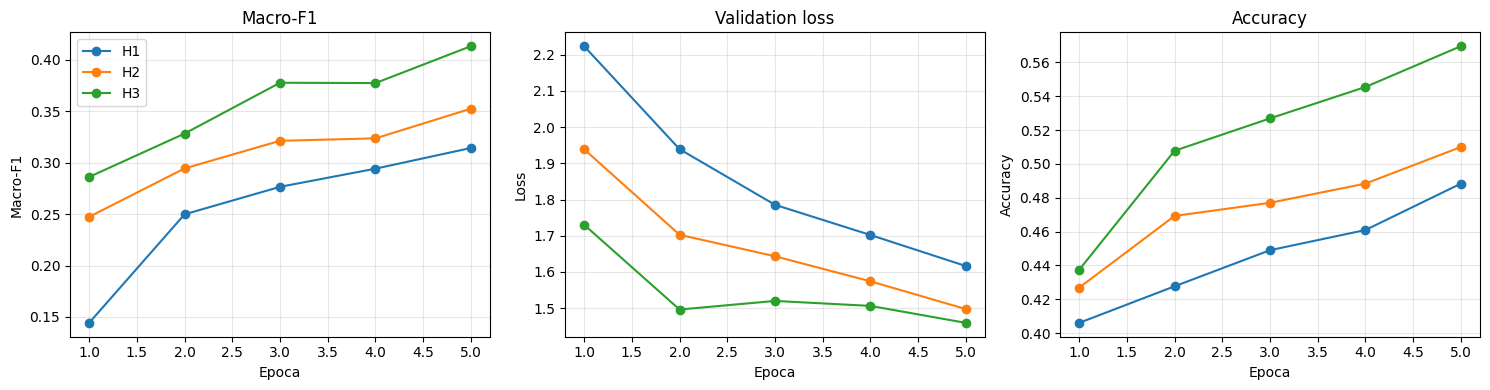

Mejor configuracion:


,experimento,epoca,lr_backbone,lr_classifier,train_loss,val_loss,macro_f1,accuracy
2,H3,5,0.00005,0.0005,0.727215,1.45945,0.413409,0.569568


In [10]:
tablas = []

for experimento in BUSQUEDA:
    ruta = DIR_HPO / f"{experimento['nombre']}_metricas.csv"
    tabla = pd.read_csv(ruta)
    assert len(tabla) == EPOCHS_HPO, (f"Experimento incompleto: {experimento['nombre']}")

    tablas.append(tabla)

historial_hpo = pd.concat(tablas, ignore_index=True)
resumen_hpo = (historial_hpo.sort_values(["macro_f1", "val_loss"], ascending=[False, True]).groupby("experimento", as_index=False).first().sort_values("macro_f1", ascending=False))
display(resumen_hpo[["experimento", "epoca", "lr_backbone", "lr_classifier", "train_loss", "val_loss", "macro_f1", "accuracy"]].round(4))
fig, ejes = plt.subplots(1, 3, figsize=(15, 4))

metricas = [("macro_f1", "Macro-F1"),("val_loss", "Validation loss"),("accuracy", "Accuracy")]
for nombre, grupo in historial_hpo.groupby("experimento"):
    for ax, (columna, titulo) in zip(ejes, metricas):
        ax.plot(grupo["epoca"], grupo[columna], marker="o", label=nombre)
        ax.set_title(titulo)
        ax.set_xlabel("Epoca")
        ax.grid(alpha=0.3)

ejes[0].set_ylabel("Macro-F1")
ejes[1].set_ylabel("Loss")
ejes[2].set_ylabel("Accuracy")
ejes[0].legend()
plt.tight_layout()
plt.show()
print("Mejor configuracion:")
display(resumen_hpo.head(1))

## Entrenamiento definitivo

Se utiliza la configuración H3, seleccionada durante la búsqueda de hiperparámetros. EfficientNet-B0 se entrena mediante fine-tuning completo, con reducción adaptativa del learning rate y parada temprana basada en Macro-F1.

In [2]:
import os
import json
import random
from google.colab import drive
from sklearn.metrics import f1_score, accuracy_score
from tqdm.auto import tqdm

drive.mount("/content/drive")

DEVICE = torch.device("cuda")

DIR_HPO = Path(
    "/content/drive/MyDrive/Proyecto_Aves/"
    "experiments/classifier/C1_EfficientNet_B0/HPO_v1"
)

mejor_hpo = json.loads((DIR_HPO / "mejor_experimento.json").read_text(encoding="utf-8"))

LR_BACKBONE = float(mejor_hpo["lr_backbone"])
LR_CLASSIFIER = float(mejor_hpo["lr_classifier"])

MAX_EPOCHS = 55
PACIENCIA = 12
MIN_DELTA = 0.001
WEIGHT_DECAY = 1e-4
DIR_FINAL = Path(
    "/content/drive/MyDrive/Proyecto_Aves/"
    "experiments/classifier/C1_EfficientNet_B0/final_v3"
)
DIR_FINAL.mkdir(parents=True, exist_ok=True)

RUTA_BEST = DIR_FINAL / "checkpoint_best.pth"
RUTA_LATEST = DIR_FINAL / "checkpoint_latest.pth"
RUTA_METRICAS = DIR_FINAL / "metricas.csv"

config_final = {
    "modelo": "EfficientNet-B0",
    "hpo_seleccionado": "H3",
    "dataset": DATASET,
    "seed": SEED,
    "lr_backbone": LR_BACKBONE,
    "lr_classifier": LR_CLASSIFIER,
    "batch_size": BATCH_SIZE,
    "weight_decay": WEIGHT_DECAY,
    "max_epochs": MAX_EPOCHS,
    "patience": PACIENCIA,
    "min_delta": MIN_DELTA,
    "train_samples": len(train_uso),
    "validation_samples": len(val_uso)
}

ruta_config = DIR_FINAL / "configuracion.json"

if ruta_config.exists():
    assert json.loads(ruta_config.read_text()) == config_final, ("La configuracion guardada es diferente")
else:
    ruta_config.write_text(json.dumps(config_final, indent=2),encoding="utf-8")

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
modelo_final = efficientnet_b0(weights=PESOS)
entradas = modelo_final.classifier[1].in_features
modelo_final.classifier[1] = nn.Linear(entradas, NUM_CLASES)
modelo_final = modelo_final.to(DEVICE)
conteos = np.bincount( train_uso["class_code"].to_numpy(), minlength=NUM_CLASES)
pesos = np.sqrt(len(train_uso) / (NUM_CLASES * conteos))
pesos /= pesos.mean()
criterio_train = nn.CrossEntropyLoss(weight=torch.tensor(pesos, dtype=torch.float32, device=DEVICE), label_smoothing=0.05)
criterio_val = nn.CrossEntropyLoss()

optimizador = torch.optim.AdamW(
    [
        {"params": modelo_final.features.parameters(), "lr": LR_BACKBONE},
        {"params": modelo_final.classifier.parameters(), "lr": LR_CLASSIFIER}
    ],
    weight_decay=WEIGHT_DECAY
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizador, mode="max", factor=0.5, patience=2, min_lr=1e-6)
scaler = torch.amp.GradScaler("cuda")
loader_val_final = DataLoader(dataset_val, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)

print("GPU:", torch.cuda.get_device_name(0))
print("LR backbone:", LR_BACKBONE)
print("LR clasificador:", LR_CLASSIFIER)
print("Resultados:", DIR_FINAL)

Mounted at /content/drive


NameError: name 'torch' is not defined

## Ejecución del fine-tuning

Se entrena EfficientNet-B0 hasta 20 épocas, conservando el mejor modelo según Macro-F1. Se guardan métricas y checkpoints para recuperar el entrenamiento si Colab se interrumpe.

In [12]:
@torch.inference_mode()
def evaluar_final():
    modelo_final.eval()
    perdida_total = 0.0
    reales, predichas = [], []

    for x, y in loader_val_final:
        x = x.to(DEVICE, non_blocking=True)
        y = y.to(DEVICE, non_blocking=True)

        with torch.autocast("cuda", dtype=torch.float16):
            salida = modelo_final(x)
            perdida = criterio_val(salida, y)

        perdida_total += perdida.item() * len(y)
        reales.extend(y.cpu().tolist())
        predichas.extend(salida.argmax(1).cpu().tolist())

    return {
        "val_loss": perdida_total / len(dataset_val),
        "macro_f1": f1_score(reales, predichas, labels=list(range(NUM_CLASES)), average="macro", zero_division=0),
        "accuracy": accuracy_score(reales, predichas)
    }


historial = []
mejor_f1 = -1.0
epocas_sin_mejora = 0
inicio = 1

if RUTA_LATEST.exists():
    estado = torch.load(RUTA_LATEST, map_location=DEVICE, weights_only=False)

    claves_compatibles = ("modelo", "hpo_seleccionado", "dataset", "seed", "lr_backbone", "lr_classifier", "batch_size", "weight_decay", "train_samples", "validation_samples",)

    for clave in claves_compatibles:
        assert estado["config"][clave] == config_final[clave], (
            f"Configuracion incompatible: {clave}"
        )

    modelo_final.load_state_dict(estado["modelo"])
    optimizador.load_state_dict(estado["optimizador"])
    scheduler.load_state_dict(estado["scheduler"])
    scaler.load_state_dict(estado["scaler"])
    torch.set_rng_state(estado["rng_torch"].cpu())
    torch.cuda.set_rng_state_all([s.cpu() for s in estado["rng_cuda"]])
    inicio = estado["epoca"] + 1
    mejor_f1 = estado["mejor_f1"]
    epocas_sin_mejora = estado["sin_mejora"]
    historial = estado["historial"]

    print("Reanudando desde epoca:", inicio)

for epoca in range(inicio, MAX_EPOCHS + 1):

    generador = torch.Generator().manual_seed(SEED + epoca)
    loader_train_final = DataLoader(dataset_train, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=True, generator=generador)
    modelo_final.train()
    perdida_total = 0.0

    for x, y in tqdm(loader_train_final, desc=f"Epoca {epoca}/{MAX_EPOCHS}", leave=False):
        x = x.to(DEVICE, non_blocking=True)
        y = y.to(DEVICE, non_blocking=True)
        optimizador.zero_grad(set_to_none=True)

        with torch.autocast("cuda", dtype=torch.float16):
            salida = modelo_final(x)
            perdida = criterio_train(salida, y)

        scaler.scale(perdida).backward()
        scaler.step(optimizador)
        scaler.update()
        perdida_total += perdida.item() * len(y)

    train_loss = perdida_total / len(dataset_train)
    metricas = evaluar_final()

    registro = {
        "epoca": epoca,
        "train_loss": train_loss,
        **metricas,
        "lr_backbone": optimizador.param_groups[0]["lr"],
        "lr_classifier": optimizador.param_groups[1]["lr"]
    }
    historial.append(registro)

    scheduler.step(metricas["macro_f1"])

    if metricas["macro_f1"] > mejor_f1 + MIN_DELTA:
        mejor_f1 = metricas["macro_f1"]
        epocas_sin_mejora = 0
        temporal = DIR_FINAL / "checkpoint_best.tmp"
        torch.save(
            {
                "model_state_dict": modelo_final.state_dict(),
                "epoca": epoca,
                "macro_f1": mejor_f1,
                "config": config_final
            },
            temporal
        )
        os.replace(temporal, RUTA_BEST)
        print("Nuevo mejor checkpoint")
    else:
        epocas_sin_mejora += 1

    temporal_csv = DIR_FINAL / "metricas.tmp"
    pd.DataFrame(historial).to_csv(temporal_csv, index=False)
    os.replace(temporal_csv, RUTA_METRICAS)

    temporal = DIR_FINAL / "checkpoint_latest.tmp"

    torch.save(
        {
            "modelo": modelo_final.state_dict(),
            "optimizador": optimizador.state_dict(),
            "scheduler": scheduler.state_dict(),
            "scaler": scaler.state_dict(),
            "rng_torch": torch.get_rng_state(),
            "rng_cuda": torch.cuda.get_rng_state_all(),
            "epoca": epoca,
            "mejor_f1": mejor_f1,
            "sin_mejora": epocas_sin_mejora,
            "historial": historial,
            "config": config_final
        },
        temporal
    )

    os.replace(temporal, RUTA_LATEST)

    print(
        f"Epoca {epoca:02d} | "
        f"Train loss: {train_loss:.4f} | "
        f"Val loss: {metricas['val_loss']:.4f} | "
        f"Macro-F1: {metricas['macro_f1']:.4f} | "
        f"Accuracy: {metricas['accuracy']:.4f}"
    )

    if epocas_sin_mejora >= PACIENCIA:
        print("Parada temprana")
        break

print("\nEntrenamiento finalizado")
print("Mejor Macro-F1:", round(mejor_f1, 4))
print("Checkpoint:", RUTA_BEST)

Epoca 1/55:   0%|          | 0/540 [00:00<?, ?it/s]

Nuevo mejor checkpoint
Epoca 01 | Train loss: 2.4384 | Val loss: 1.7605 | Macro-F1: 0.3039 | Accuracy: 0.4557


Epoca 2/55:   0%|          | 0/540 [00:00<?, ?it/s]

Nuevo mejor checkpoint
Epoca 02 | Train loss: 1.8160 | Val loss: 1.6073 | Macro-F1: 0.3338 | Accuracy: 0.5053


Epoca 3/55:   0%|          | 0/540 [00:00<?, ?it/s]

Nuevo mejor checkpoint
Epoca 03 | Train loss: 1.5774 | Val loss: 1.5203 | Macro-F1: 0.3797 | Accuracy: 0.5266


... (100 outputs left out)

Epoca 54/55:   0%|          | 0/540 [00:00<?, ?it/s]

Epoca 54 | Train loss: 0.6540 | Val loss: 1.3521 | Macro-F1: 0.5024 | Accuracy: 0.6680


Epoca 55/55:   0%|          | 0/540 [00:00<?, ?it/s]

Epoca 55 | Train loss: 0.6552 | Val loss: 1.3616 | Macro-F1: 0.5046 | Accuracy: 0.6691

Entrenamiento finalizado
Mejor Macro-F1: 0.5093
Checkpoint: /content/drive/MyDrive/Proyecto_Aves/experiments/classifier/C1_EfficientNet_B0/final_v3/checkpoint_best.pth


## Resultados del entrenamiento

Se guardan las curvas de aprendizaje y se libera la GPU una vez finalizado el entrenamiento

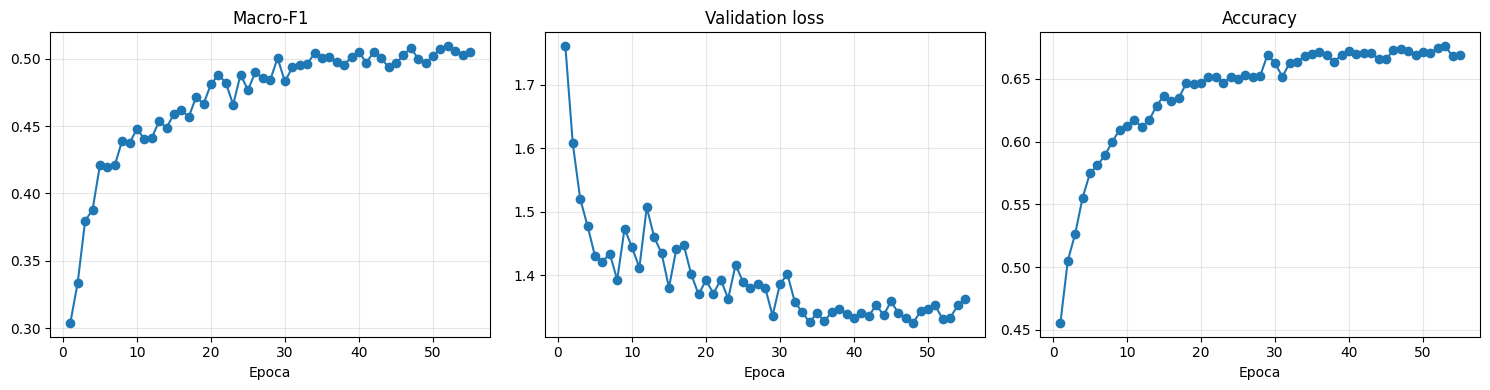

Mejor Macro-F1: 0.5093
Resultados guardados: /content/drive/MyDrive/Proyecto_Aves/experiments/classifier/C1_EfficientNet_B0/final_v3


In [ ]:
from google.colab import runtime
import matplotlib.pyplot as plt

assert RUTA_BEST.is_file()
assert RUTA_METRICAS.is_file()

metricas_final = pd.read_csv(RUTA_METRICAS)

fig, ejes = plt.subplots(1, 3, figsize=(15, 4))

for ax, columna, titulo in zip(
    ejes,
    ["macro_f1", "val_loss", "accuracy"],
    ["Macro-F1", "Validation loss", "Accuracy"]
):
    ax.plot(metricas_final["epoca"], metricas_final[columna], marker="o")
    ax.set_title(titulo)
    ax.set_xlabel("Epoca")
    ax.grid(alpha=0.3)

plt.tight_layout()

fig.savefig(
    DIR_FINAL / "curvas_entrenamiento.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

print("Mejor Macro-F1:", round(metricas_final["macro_f1"].max(), 4))
print("Resultados guardados:", DIR_FINAL)

drive.flush_and_unmount()
runtime.unassign()

## Extensión del entrenamiento: final_v4

Se continúa el fine-tuning desde la época 55 de final_v3, manteniendo el estado del modelo, optimizador y scheduler. Se permiten hasta 70 épocas adicionales con paciencia de 12.

In [4]:
import os
import json
import shutil
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from pathlib import Path
from google.colab import drive
from sklearn.metrics import f1_score, accuracy_score
from tqdm.auto import tqdm
from torch.utils.data import DataLoader
from torchvision.models import efficientnet_b0

assert torch.cuda.is_available(), "Selecciona GPU T4"
drive.mount("/content/drive")

DEVICE = torch.device("cuda")

DIR_BASE = Path(
    "/content/drive/MyDrive/Proyecto_Aves/"
    "experiments/classifier/C1_EfficientNet_B0"
)

DIR_ORIGEN = DIR_BASE / "final_v3"
DIR_FINAL = DIR_BASE / "final_v4"
DIR_FINAL.mkdir(parents=True, exist_ok=True)

EPOCA_ORIGEN = 55
EPOCAS_ADICIONALES = 70
MAX_EPOCHS = EPOCA_ORIGEN + EPOCAS_ADICIONALES

PACIENCIA = 12
MIN_DELTA = 0.001
LABEL_SMOOTHING = 0.05
WEIGHT_DECAY = 1e-4

RUTA_BEST = DIR_FINAL / "checkpoint_best.pth"
RUTA_LATEST = DIR_FINAL / "checkpoint_latest.pth"
RUTA_METRICAS = DIR_FINAL / "metricas.csv"

# Copiar el estado original una sola vez
archivos = (
    "checkpoint_best.pth",
    "checkpoint_latest.pth",
    "metricas.csv"
)

if not RUTA_LATEST.exists():
    assert not any((DIR_FINAL / f).exists() for f in archivos), (
        "La carpeta final_v4 contiene una copia incompleta"
    )

    for archivo in archivos:
        origen = DIR_ORIGEN / archivo
        assert origen.is_file(), f"Falta {origen}"
        shutil.copy2(origen, DIR_FINAL / archivo)

assert all((DIR_FINAL / f).is_file() for f in archivos)

CONFIG_EXTENSION = {
    "origen": "final_v3",
    "epoca_origen": EPOCA_ORIGEN,
    "max_epochs": MAX_EPOCHS,
    "patience": PACIENCIA,
    "min_delta": MIN_DELTA,
    "label_smoothing": LABEL_SMOOTHING,
    "reset_patience_on_extension": True
}

ruta_config = DIR_FINAL / "configuracion_extension.json"

if ruta_config.exists():
    assert json.loads(ruta_config.read_text()) == CONFIG_EXTENSION
else:
    ruta_config.write_text(
        json.dumps(CONFIG_EXTENSION, indent=2),
        encoding="utf-8"
    )

print("GPU:", torch.cuda.get_device_name(0))
print("Epocas acumuladas maximas:", MAX_EPOCHS)
print("Epocas adicionales:", EPOCAS_ADICIONALES)
print("Paciencia:", PACIENCIA)
print("Directorio:", DIR_FINAL)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU: Tesla T4
Epocas acumuladas maximas: 125
Epocas adicionales: 70
Paciencia: 12
Directorio: /content/drive/MyDrive/Proyecto_Aves/experiments/classifier/C1_EfficientNet_B0/final_v4


## Continuación del fine-tuning

Se restauran los pesos, el optimizador, el scheduler y la precisión mixta. Se continúa desde la siguiente época pendiente y se guardan el mejor checkpoint y el estado completo al finalizar cada época.

In [10]:
from pathlib import Path
from google.colab import drive
import shutil

drive.mount("/content/drive", force_remount=False)

DIR_BASE = Path(
    "/content/drive/MyDrive/Proyecto_Aves/"
    "experiments/classifier/C1_EfficientNet_B0"
)

DIR_ORIGEN = DIR_BASE / "final_v3"
DIR_FINAL = DIR_BASE / "final_v4"
DIR_FINAL.mkdir(parents=True, exist_ok=True)

archivos = (
    "checkpoint_latest.pth",
    "checkpoint_best.pth",
    "metricas.csv"
)

for archivo in archivos:
    origen = DIR_ORIGEN / archivo
    destino = DIR_FINAL / archivo

    assert origen.is_file(), f"No existe el archivo original: {origen}"

    if not destino.exists():
        # No mezclar checkpoints antiguos con una continuación parcial
        if archivo == "checkpoint_latest.pth":
            assert not any(
                (DIR_FINAL / f).exists()
                for f in ("checkpoint_best.pth", "metricas.csv")
            ), "final_v4 contiene archivos parciales; revisarlos antes de copiar"

        shutil.copy2(origen, destino)
        print(f"Copiado: {archivo}")
    else:
        print(f"Ya existe: {archivo}")

RUTA_LATEST = DIR_FINAL / "checkpoint_latest.pth"
RUTA_BEST = DIR_FINAL / "checkpoint_best.pth"
RUTA_METRICAS = DIR_FINAL / "metricas.csv"

assert all((DIR_FINAL / f).is_file() for f in archivos)

print("\nArchivos disponibles:")
for archivo in archivos:
    ruta = DIR_FINAL / archivo
    print(f"{archivo}: {ruta.stat().st_size / 1024**2:.2f} MB")

print("\nDirectorio:", DIR_FINAL)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Ya existe: checkpoint_latest.pth
Ya existe: checkpoint_best.pth
Ya existe: metricas.csv

Archivos disponibles:
checkpoint_latest.pth: 46.79 MB
checkpoint_best.pth: 15.73 MB
metricas.csv: 0.00 MB

Directorio: /content/drive/MyDrive/Proyecto_Aves/experiments/classifier/C1_EfficientNet_B0/final_v4


In [11]:
estado = torch.load(
    RUTA_LATEST,
    map_location=DEVICE,
    weights_only=False
)

assert EPOCA_ORIGEN <= estado["epoca"] <= MAX_EPOCHS
assert estado["config"]["modelo"] == "EfficientNet-B0"
assert estado["config"]["seed"] == SEED
assert estado["config"]["batch_size"] == BATCH_SIZE

if "label_smoothing" in estado["config"]:
    assert estado["config"]["label_smoothing"] == LABEL_SMOOTHING

if "extension" in estado:
    assert estado["extension"] == CONFIG_EXTENSION

# Reconstruir arquitectura
modelo_final = efficientnet_b0(weights=None)
entradas = modelo_final.classifier[1].in_features
modelo_final.classifier[1] = nn.Linear(entradas, NUM_CLASES)
modelo_final = modelo_final.to(DEVICE)

modelo_final.load_state_dict(estado["modelo"])

# Mantener la misma función de pérdida
conteos = np.bincount(
    train_uso["class_code"].to_numpy(),
    minlength=NUM_CLASES
)

pesos = np.sqrt(len(train_uso) / (NUM_CLASES * conteos))
pesos /= pesos.mean()

criterio_train = nn.CrossEntropyLoss(
    weight=torch.tensor(
        pesos, dtype=torch.float32, device=DEVICE
    ),
    label_smoothing=LABEL_SMOOTHING
)

criterio_val = nn.CrossEntropyLoss()

# Restaurar optimizador y scheduler
optimizador = torch.optim.AdamW(
    [
        {
            "params": modelo_final.features.parameters(),
            "lr": estado["config"]["lr_backbone"]
        },
        {
            "params": modelo_final.classifier.parameters(),
            "lr": estado["config"]["lr_classifier"]
        }
    ],
    weight_decay=WEIGHT_DECAY
)

optimizador.load_state_dict(estado["optimizador"])

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizador,
    mode="max",
    factor=0.5,
    patience=2,
    min_lr=1e-6
)
scheduler.load_state_dict(estado["scheduler"])

scaler = torch.amp.GradScaler("cuda")
scaler.load_state_dict(estado["scaler"])

# Recuperar generadores aleatorios
torch.set_rng_state(estado["rng_torch"].cpu())
torch.cuda.set_rng_state_all(
    [s.cpu() for s in estado["rng_cuda"]]
)

inicio = estado["epoca"] + 1
mejor_f1 = estado["mejor_f1"]
historial = estado["historial"]

assert historial[-1]["epoca"] == estado["epoca"]

# Paciencia nueva al comenzar la extensión
if estado["epoca"] == EPOCA_ORIGEN and "extension" not in estado:
    epocas_sin_mejora = 0
else:
    epocas_sin_mejora = estado["sin_mejora"]

print("Reanudando desde epoca:", inicio)
print("Mejor Macro-F1 anterior:", round(mejor_f1, 4))
print("LR backbone:", optimizador.param_groups[0]["lr"])
print("LR classifier:", optimizador.param_groups[1]["lr"])


loader_val_final = DataLoader(
    dataset_val,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)


@torch.inference_mode()
def evaluar_extension():
    modelo_final.eval()

    perdida_total = 0.0
    reales, predichas = [], []

    for x, y in loader_val_final:
        x = x.to(DEVICE, non_blocking=True)
        y = y.to(DEVICE, non_blocking=True)

        with torch.autocast("cuda", dtype=torch.float16):
            salida = modelo_final(x)
            perdida = criterio_val(salida, y)

        perdida_total += perdida.item() * len(y)

        reales.extend(y.cpu().tolist())
        predichas.extend(salida.argmax(1).cpu().tolist())

    return {
        "val_loss": perdida_total / len(dataset_val),
        "macro_f1": f1_score(
            reales,
            predichas,
            labels=list(range(NUM_CLASES)),
            average="macro",
            zero_division=0
        ),
        "accuracy": accuracy_score(reales, predichas)
    }


for epoca in range(inicio, MAX_EPOCHS + 1):

    generador = torch.Generator().manual_seed(SEED + epoca)

    loader_train_final = DataLoader(
        dataset_train,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=0,
        pin_memory=True,
        generator=generador
    )

    modelo_final.train()
    perdida_total = 0.0

    for x, y in tqdm(
        loader_train_final,
        desc=f"Epoca {epoca}/{MAX_EPOCHS}",
        leave=False
    ):
        x = x.to(DEVICE, non_blocking=True)
        y = y.to(DEVICE, non_blocking=True)

        optimizador.zero_grad(set_to_none=True)

        with torch.autocast("cuda", dtype=torch.float16):
            salida = modelo_final(x)
            perdida = criterio_train(salida, y)

        scaler.scale(perdida).backward()
        scaler.step(optimizador)
        scaler.update()

        perdida_total += perdida.item() * len(y)

    train_loss = perdida_total / len(dataset_train)
    metricas = evaluar_extension()

    registro = {
        "epoca": epoca,
        "train_loss": train_loss,
        **metricas,
        "lr_backbone": optimizador.param_groups[0]["lr"],
        "lr_classifier": optimizador.param_groups[1]["lr"]
    }
    historial.append(registro)

    scheduler.step(metricas["macro_f1"])

    if metricas["macro_f1"] > mejor_f1 + MIN_DELTA:
        mejor_f1 = metricas["macro_f1"]
        epocas_sin_mejora = 0

        temporal = DIR_FINAL / "checkpoint_best.tmp"

        torch.save(
            {
                "model_state_dict": modelo_final.state_dict(),
                "epoca": epoca,
                "macro_f1": mejor_f1,
                "config": estado["config"],
                "extension": CONFIG_EXTENSION
            },
            temporal
        )

        os.replace(temporal, RUTA_BEST)
        print("Nuevo mejor checkpoint")
    else:
        epocas_sin_mejora += 1

    temporal_csv = DIR_FINAL / "metricas.tmp"
    pd.DataFrame(historial).to_csv(temporal_csv, index=False)
    os.replace(temporal_csv, RUTA_METRICAS)

    temporal = DIR_FINAL / "checkpoint_latest.tmp"

    torch.save(
        {
            "modelo": modelo_final.state_dict(),
            "optimizador": optimizador.state_dict(),
            "scheduler": scheduler.state_dict(),
            "scaler": scaler.state_dict(),
            "rng_torch": torch.get_rng_state(),
            "rng_cuda": torch.cuda.get_rng_state_all(),
            "epoca": epoca,
            "mejor_f1": mejor_f1,
            "sin_mejora": epocas_sin_mejora,
            "historial": historial,
            "config": estado["config"],
            "extension": CONFIG_EXTENSION
        },
        temporal
    )

    os.replace(temporal, RUTA_LATEST)

    print(
        f"Epoca {epoca:03d} | "
        f"Train loss: {train_loss:.4f} | "
        f"Val loss: {metricas['val_loss']:.4f} | "
        f"Macro-F1: {metricas['macro_f1']:.4f} | "
        f"Accuracy: {metricas['accuracy']:.4f} | "
        f"Sin mejora: {epocas_sin_mejora}/{PACIENCIA}"
    )

    if epocas_sin_mejora >= PACIENCIA:
        print("Parada temprana")
        break

print("\nEntrenamiento finalizado")
print("Ultima epoca:", historial[-1]["epoca"])
print("Mejor Macro-F1:", round(mejor_f1, 4))
print("Checkpoint:", RUTA_BEST)

Reanudando desde epoca: 56
Mejor Macro-F1 anterior: 0.5093
LR backbone: 1.5625e-06
LR classifier: 1.5625e-05


Epoca 56/125:   0%|          | 0/540 [00:00<?, ?it/s]

Epoca 056 | Train loss: 0.6529 | Val loss: 1.3393 | Macro-F1: 0.5020 | Accuracy: 0.6716 | Sin mejora: 1/12


Epoca 57/125:   0%|          | 0/540 [00:00<?, ?it/s]

Nuevo mejor checkpoint
Epoca 057 | Train loss: 0.6555 | Val loss: 1.3378 | Macro-F1: 0.5109 | Accuracy: 0.6746 | Sin mejora: 0/12


Epoca 58/125:   0%|          | 0/540 [00:00<?, ?it/s]

... (19 outputs left out)

Epoca 68/125:   0%|          | 0/540 [00:00<?, ?it/s]

Epoca 068 | Train loss: 0.6520 | Val loss: 1.3388 | Macro-F1: 0.5099 | Accuracy: 0.6757 | Sin mejora: 11/12


Epoca 69/125:   0%|          | 0/540 [00:00<?, ?it/s]

Epoca 069 | Train loss: 0.6519 | Val loss: 1.3533 | Macro-F1: 0.5083 | Accuracy: 0.6732 | Sin mejora: 12/12
Parada temprana

Entrenamiento finalizado
Ultima epoca: 69
Mejor Macro-F1: 0.5109
Checkpoint: /content/drive/MyDrive/Proyecto_Aves/experiments/classifier/C1_EfficientNet_B0/final_v4/checkpoint_best.pth


## Análisis de la continuación

Se visualiza la evolución acumulada del entrenamiento, incluyendo Macro-F1, validation loss, accuracy y learning rates. Se conserva el mejor modelo y se libera la GPU.

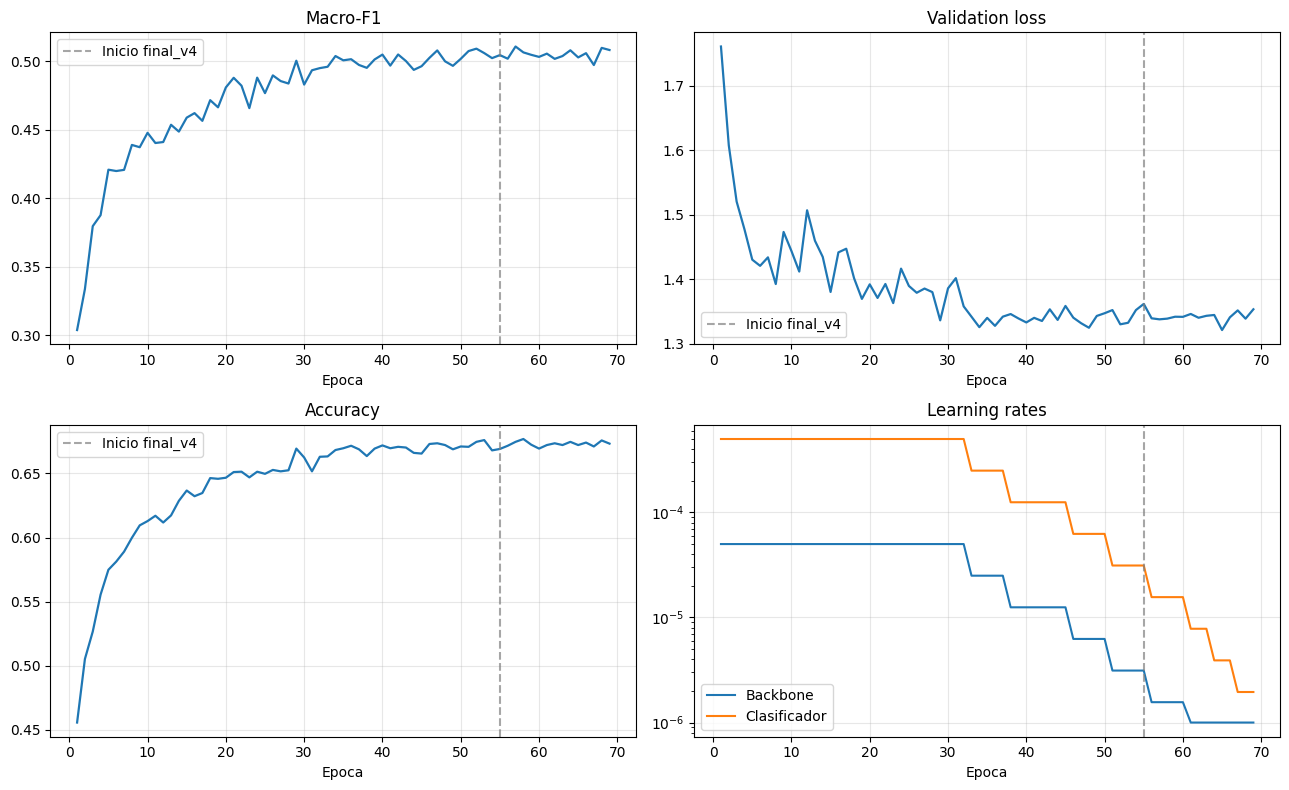

Ultima epoca: 69
Mejor epoca: 57
Mejor Macro-F1: 0.5109
Accuracy en mejor epoca: 0.6746
Resultados: /content/drive/MyDrive/Proyecto_Aves/experiments/classifier/C1_EfficientNet_B0/final_v4


In [5]:
import matplotlib.pyplot as plt
from google.colab import runtime

assert RUTA_METRICAS.is_file()
assert RUTA_BEST.is_file()

metricas_final = pd.read_csv(RUTA_METRICAS)

mejor = metricas_final.loc[
    metricas_final["macro_f1"].idxmax()
]

fig, ejes = plt.subplots(2, 2, figsize=(13, 8))

graficos = [
    ("macro_f1", "Macro-F1"),
    ("val_loss", "Validation loss"),
    ("accuracy", "Accuracy")
]

for ax, (columna, titulo) in zip(ejes.flat[:3], graficos):
    ax.plot(
        metricas_final["epoca"],
        metricas_final[columna],
        linewidth=1.6
    )

    ax.axvline(
        EPOCA_ORIGEN,
        color="gray",
        linestyle="--",
        alpha=0.7,
        label="Inicio final_v4"
    )

    ax.set_title(titulo)
    ax.set_xlabel("Epoca")
    ax.grid(alpha=0.3)
    ax.legend()

ax = ejes.flat[3]

ax.plot(
    metricas_final["epoca"],
    metricas_final["lr_backbone"],
    label="Backbone"
)

ax.plot(
    metricas_final["epoca"],
    metricas_final["lr_classifier"],
    label="Clasificador"
)

ax.axvline(
    EPOCA_ORIGEN,
    color="gray",
    linestyle="--",
    alpha=0.7
)

ax.set_yscale("log")
ax.set_title("Learning rates")
ax.set_xlabel("Epoca")
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()

fig.savefig(
    DIR_FINAL / "curvas_entrenamiento.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

print("Ultima epoca:", int(metricas_final["epoca"].max()))
print("Mejor epoca:", int(mejor["epoca"]))
print("Mejor Macro-F1:", round(float(mejor["macro_f1"]), 4))
print("Accuracy en mejor epoca:", round(float(mejor["accuracy"]), 4))
print("Resultados:", DIR_FINAL)

# Sincronizar Drive y liberar GPU
drive.flush_and_unmount()
runtime.unassign()

## Evaluación detallada sobre validation

Se recupera el mejor checkpoint de EfficientNet-B0 y se generan predicciones para los 3.608 eventos elegibles de validation. Los resultados se almacenan para realizar el análisis por clase y fuente.

In [7]:
  from google.colab import drive
from sklearn.metrics import (classification_report, confusion_matrix, f1_score, accuracy_score)
from torchvision.models import efficientnet_b0
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

drive.mount("/content/drive")

DIR_EVAL = Path(
    "/content/drive/MyDrive/Proyecto_Aves/"
    "experiments/classifier/C1_EfficientNet_B0/final_v4"
)

NUM_CLASES = len(codigos)
DEVICE_EVAL = torch.device("cpu")
checkpoint = torch.load(DIR_EVAL / "checkpoint_best.pth", map_location="cpu", weights_only=True)
modelo_eval = efficientnet_b0(weights=None)
entradas = modelo_eval.classifier[1].in_features
modelo_eval.classifier[1] = nn.Linear(entradas, NUM_CLASES)
modelo_eval.load_state_dict(checkpoint["model_state_dict"])
modelo_eval = modelo_eval.to(DEVICE_EVAL).eval()
loader_eval = DataLoader(dataset_val, batch_size=32, shuffle=False, num_workers=0)
predicciones = []
confianzas = []

with torch.inference_mode():
    for x, _ in tqdm(loader_eval, desc="Evaluando validation"):
        salida = modelo_eval(x.to(DEVICE_EVAL))
        probabilidades = salida.softmax(dim=1)
        confianza, prediccion = probabilidades.max(dim=1)

        predicciones.extend(prediccion.cpu().tolist())
        confianzas.extend(confianza.cpu().tolist())

resultados_val = val_uso.reset_index(drop=True).copy()

assert len(predicciones) == len(resultados_val)

resultados_val["pred_code"] = predicciones
resultados_val["pred_label"] = resultados_val["pred_code"].map(codigos)
resultados_val["confianza"] = confianzas
resultados_val["correcto"] = (resultados_val["class_code"] == resultados_val["pred_code"])
resultados_val.to_csv(DIR_EVAL / "predicciones_validation.csv", index=False)
y_true = resultados_val["class_code"].to_numpy()
y_pred = resultados_val["pred_code"].to_numpy()

print("Checkpoint, epoca:", checkpoint["epoca"])
print("Eventos evaluados:", len(resultados_val))
print("Macro-F1:", round(f1_score(y_true, y_pred, average="macro"), 4))
print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
print("Predicciones guardadas")

Mounted at /content/drive


Evaluando validation:   0%|          | 0/113 [00:00<?, ?it/s]

Checkpoint, epoca: 57
Eventos evaluados: 3608
Macro-F1: 0.5115
Accuracy: 0.6743
Predicciones guardadas


## Desempeño por especie

Se calculan precision, recall y F1 para las 31 clases. Se incluyen los tamaños de muestra para identificar resultados poco confiables en especies minoritarias.

In [8]:
reporte = classification_report(y_true, y_pred, labels=list(range(NUM_CLASES)), target_names=[str(i) for i in range(NUM_CLASES)], output_dict=True, zero_division=0)
filas = []

for codigo in range(NUM_CLASES):
    m = reporte[str(codigo)]
    filas.append({
        "codigo": codigo,
        "especie": codigos[codigo],
        "n_train": int((train_uso["class_code"] == codigo).sum()),
        "n_validation": int(m["support"]),
        "precision": m["precision"],
        "recall": m["recall"],
        "f1": m["f1-score"]
    })

metricas_clase = pd.DataFrame(filas).sort_values("f1")
metricas_clase.to_csv(DIR_EVAL / "metricas_por_clase.csv", index=False)
display(metricas_clase.round(4))

print("Macro-Precision:", round(reporte["macro avg"]["precision"], 4))
print("Macro-Recall:", round(reporte["macro avg"]["recall"], 4))
print("Macro-F1:", round(reporte["macro avg"]["f1-score"], 4))
print("Weighted-F1:", round(reporte["weighted avg"]["f1-score"], 4))

print("\nEspecies con F1 inferior a 0.30:")
display(metricas_clase[metricas_clase["f1"] < 0.30].round(4))

,codigo,especie,n_train,n_validation,precision,recall,f1
12,12,dendrocolaptes certhia,200,1,0.0000,0.0000,0.0000
14,14,leptotila rufaxilla,291,24,0.0000,0.0000,0.0000
20,20,patagioenas plumbea,185,41,0.0000,0.0000,0.0000
19,19,pachyramphus polychopterus,80,10,0.2500,0.1000,0.1429
24,24,ramphastos tucanus,179,44,0.2432,0.2045,0.2222
3,3,attila spadiceus,122,34,0.2800,0.2059,0.2373
21,21,pheugopedius rutilus,291,23,0.4167,0.2174,0.2857
9,9,crypturellus soui,155,22,0.2424,0.3636,0.2909
25,25,synallaxis azarae,206,22,0.2200,0.5000,0.3056
22,22,pitangus sulphuratus,299,79,0.5000,0.2405,0.3248


Macro-Precision: 0.5242
Macro-Recall: 0.5268
Macro-F1: 0.5115
Weighted-F1: 0.6636

Especies con F1 inferior a 0.30:


,codigo,especie,n_train,n_validation,precision,recall,f1
12,12,dendrocolaptes certhia,200,1,0.0000,0.0000,0.0000
14,14,leptotila rufaxilla,291,24,0.0000,0.0000,0.0000
20,20,patagioenas plumbea,185,41,0.0000,0.0000,0.0000
19,19,pachyramphus polychopterus,80,10,0.2500,0.1000,0.1429
24,24,ramphastos tucanus,179,44,0.2432,0.2045,0.2222
3,3,attila spadiceus,122,34,0.2800,0.2059,0.2373
21,21,pheugopedius rutilus,291,23,0.4167,0.2174,0.2857
9,9,crypturellus soui,155,22,0.2424,0.3636,0.2909


## Análisis de errores


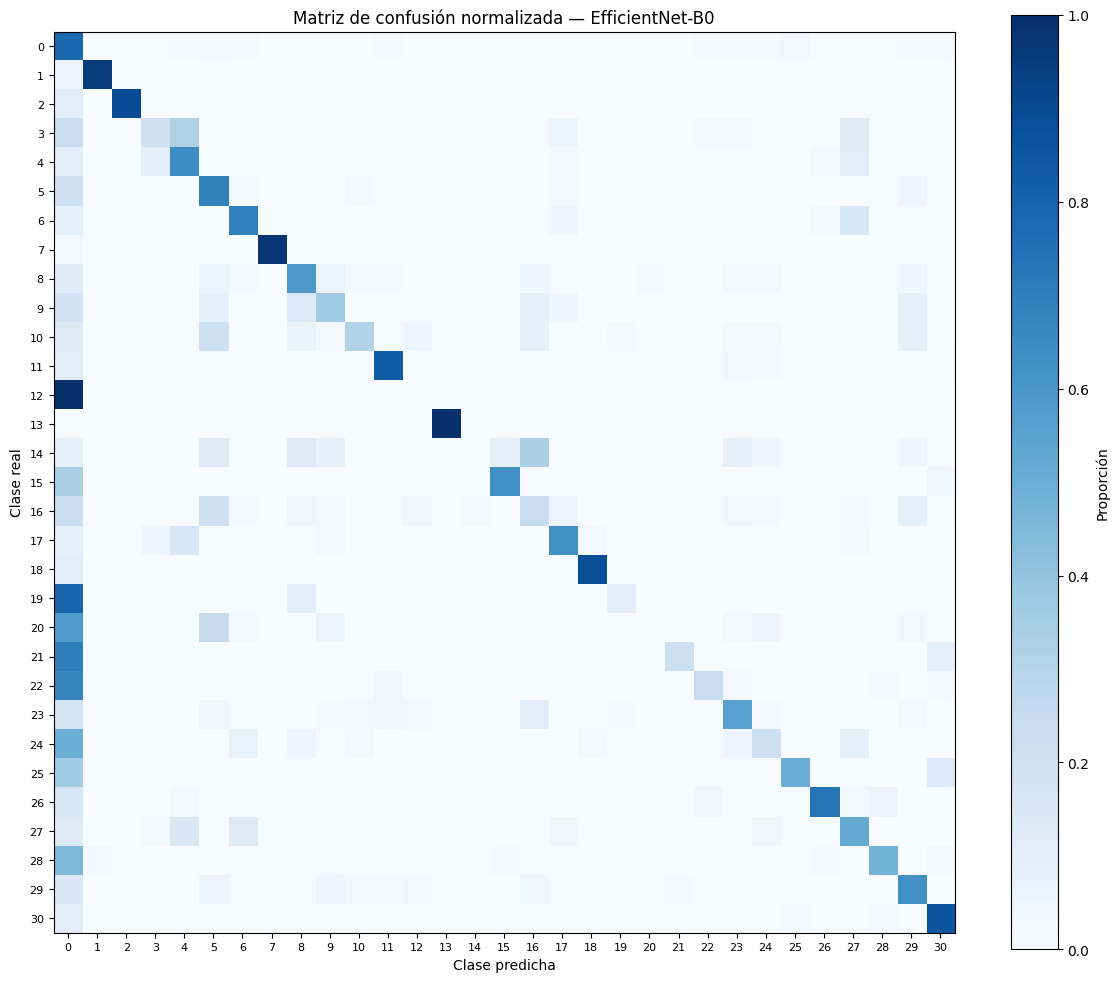

Confusiones mas frecuentes:


,clase_real,clase_predicha,eventos
135,pitangus sulphuratus,OTHER_SPECIES,53
102,momotus momota,OTHER_SPECIES,48
103,momotus momota,campylorhynchus turdinus,44
170,tyrannus melancholicus,OTHER_SPECIES,39
24,OTHER_SPECIES,synallaxis azarae,35
43,campylorhynchus turdinus,OTHER_SPECIES,31
4,OTHER_SPECIES,campylorhynchus turdinus,30
187,zonotrichia capensis,OTHER_SPECIES,29
175,xiphorhynchus guttatus,OTHER_SPECIES,24
126,patagioenas plumbea,OTHER_SPECIES,24


,fuente,eventos,clases_presentes,accuracy,macro_f1_clases_presentes
0,Col-CR,480,6,0.7875,0.4404
1,Peru,921,13,0.4484,0.3177
2,PteroSet,822,14,0.6922,0.4225
3,WABAD-CO,1385,21,0.7747,0.5811


Nota: Macro-F1 por fuente utiliza solo las clases presentes en cada fuente; los valores no son directamente comparables si difieren sus clases.


In [9]:
matriz = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASES)))
matriz_normalizada = matriz / np.maximum(matriz.sum(axis=1, keepdims=True), 1)
pd.DataFrame(matriz, index=[codigos[i] for i in range(NUM_CLASES)], columns=[codigos[i] for i in range(NUM_CLASES)]).to_csv(DIR_EVAL / "matriz_confusion.csv")

fig, ax = plt.subplots(figsize=(12, 10))
imagen = ax.imshow(matriz_normalizada, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(NUM_CLASES))
ax.set_yticks(range(NUM_CLASES))
ax.set_xticklabels(range(NUM_CLASES), fontsize=8)
ax.set_yticklabels(range(NUM_CLASES), fontsize=8)
ax.set_xlabel("Clase predicha")
ax.set_ylabel("Clase real")
ax.set_title("Matriz de confusión normalizada — EfficientNet-B0")
fig.colorbar(imagen, ax=ax, label="Proporción")
plt.tight_layout()
fig.savefig(DIR_EVAL / "matriz_confusion.png", dpi=180, bbox_inches="tight")
plt.show()

errores = []
for real in range(NUM_CLASES):
    for predicha in range(NUM_CLASES):
        if real != predicha and matriz[real, predicha] > 0:
            errores.append({
                "clase_real": codigos[real],
                "clase_predicha": codigos[predicha],
                "eventos": int(matriz[real, predicha])
            })

errores_frecuentes = (pd.DataFrame(errores).sort_values("eventos", ascending=False))
print("Confusiones mas frecuentes:")
display(errores_frecuentes.head(15))
errores_frecuentes.to_csv(DIR_EVAL / "confusiones_frecuentes.csv", index=False)
columna_fuente = next(
    (c for c in ("dataset", "dataset_origen", "source_dataset", "corpus")
     if c in resultados_val.columns),
    None
)

if columna_fuente:
    resumen_fuentes = []

    for fuente, grupo in resultados_val.groupby(columna_fuente):
        clases_presentes = sorted(grupo["class_code"].unique())

        resumen_fuentes.append({
            "fuente": fuente,
            "eventos": len(grupo),
            "clases_presentes": len(clases_presentes),
            "accuracy": accuracy_score(grupo["class_code"], grupo["pred_code"]),
            "macro_f1_clases_presentes": f1_score(grupo["class_code"], grupo["pred_code"], labels=clases_presentes, average="macro", zero_division=0)
        })

    tabla_fuentes = pd.DataFrame(resumen_fuentes)
    display(tabla_fuentes.round(4))

    tabla_fuentes.to_csv(DIR_EVAL / "metricas_por_fuente.csv", index=False)
    print(
        "Nota: Macro-F1 por fuente utiliza solo las clases "
        "presentes en cada fuente; los valores no son "
        "directamente comparables si difieren sus clases."
    )
else:
    print("No se encontro una columna de origen en el manifest.")

## Conclusiones

El clasificador EfficientNet-B0, entrenado mediante transfer learning y fine-tuning completo, alcanzó un **Macro-F1 de aproximadamente 0,51** sobre el conjunto de validación, utilizando 31 clases y separación de datos por grabación.

La búsqueda de hiperparámetros y los experimentos posteriores permitieron mejorar progresivamente el desempeño. Sin embargo, el análisis por clase evidenció diferencias importantes: algunas especies alcanzaron valores de F1 superiores a 0,90, mientras que otras presentaron resultados inferiores a 0,30 o incluso nulos.

La matriz de confusión identificó una tendencia a clasificar vocalizaciones de determinadas especies objetivo como `OTHER_SPECIES`, además de confusiones entre especies específicas. El desempeño también varió entre los corpus de origen, aunque estas diferencias deben interpretarse considerando sus distintas distribuciones de clases.

En conclusión, **EfficientNet-B0 constituye una línea base válida para comparar arquitecturas de clasificación acústica**, pero su rendimiento no es suficientemente uniforme entre especies. Se conserva el mejor checkpoint y se continuará con Swin-T, utilizando el mismo conjunto de datos y protocolo de evaluación para determinar si una arquitectura basada en Transformers mejora el desempeño.